In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv(r'/content/Unemployment in India.csv')

In [ ]:
df.shape

(768, 7)

In [ ]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


Here after df.info() we find out that the dataset contains categorical as well as numerical values that will be handled later

In [ ]:
df.isnull().sum()

,0
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


We find out that from 768 rows there are 28 rows which are null

In [ ]:
df[df["Region"].isna()].isnull().all(axis=1).value_counts()

,count
True,28


From here we verify that the complete rows are null, i.e., there isnt only one column value empty the entire rows are null

In [ ]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [ ]:
df.dtypes

,0
Region,object
Date,object
Frequency,object
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,object


Above we found all rows are null so we drop those rows

In [ ]:
df=df.dropna(how="all")

We now observe that the new shape is 740

In [ ]:
df[df.duplicated()]

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area


In [ ]:
df.duplicated().sum()

np.int64(0)

Dropping the null values led the duplicated values to get eliminated

Now handling the Date feature

In [ ]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [ ]:
df[' Date'].dtype

dtype('O')

In [ ]:
df[' Date'] = pd.to_datetime(df[' Date'], dayfirst=True)

In [ ]:
df[' Date'].dtype

dtype('<M8[ns]')

#EDA

Region-wise average unemployment rates

In [ ]:
region_avg=df.groupby("Region")[" Estimated Unemployment Rate (%)"].mean()

In [ ]:
region_avg

,Estimated Unemployment Rate (%)
Region,
Andhra Pradesh,7.477143
Assam,6.428077
Bihar,18.918214
Chandigarh,15.991667
Chhattisgarh,9.240357
Delhi,16.495357
Goa,9.274167
Gujarat,6.663929
Haryana,26.283214


We get the average unemployment rates, region-wise

We now sort them to understand the highest rate

In [ ]:
region_avg=region_avg.sort_values(ascending=False)

In [ ]:
region_avg

,Estimated Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


In [ ]:
top_10=region_avg.head(10)
top_10_df=top_10.reset_index()

##Top 10 states with highest average unemployment rate

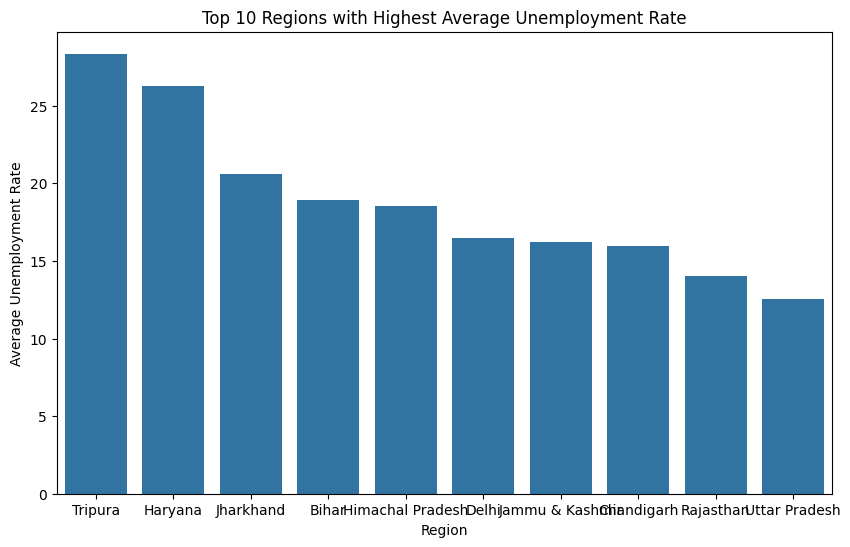

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(x="Region",y=" Estimated Unemployment Rate (%)",data=top_10_df)
plt.xlabel("Region")
plt.ylabel("Average Unemployment Rate")
plt.title("Top 10 Regions with Highest Average Unemployment Rate")
plt.show()

Tripura and Haryana have the highest average unemployment rates among the regions in the dataset, followed by Jharkhand, Bihar, and Himachal Pradesh. The substantial variation across regions suggests that unemployment levels differ considerably across India during the period covered by the dataset. However, this chart only shows regional differences and does not establish the reasons behind them.

##Month-wise unemployment trend

In [ ]:
monthly_unemployment = df.groupby(" Date")[" Estimated Unemployment Rate (%)"].mean()
monthly_unemployment

,Estimated Unemployment Rate (%)
Date,
2019-05-31,8.874259
2019-06-30,9.303333
2019-07-31,9.033889
2019-08-31,9.637925
2019-09-30,9.051731
2019-10-31,9.900909
2019-11-30,9.868364
2019-12-31,9.497358
2020-01-31,9.950755


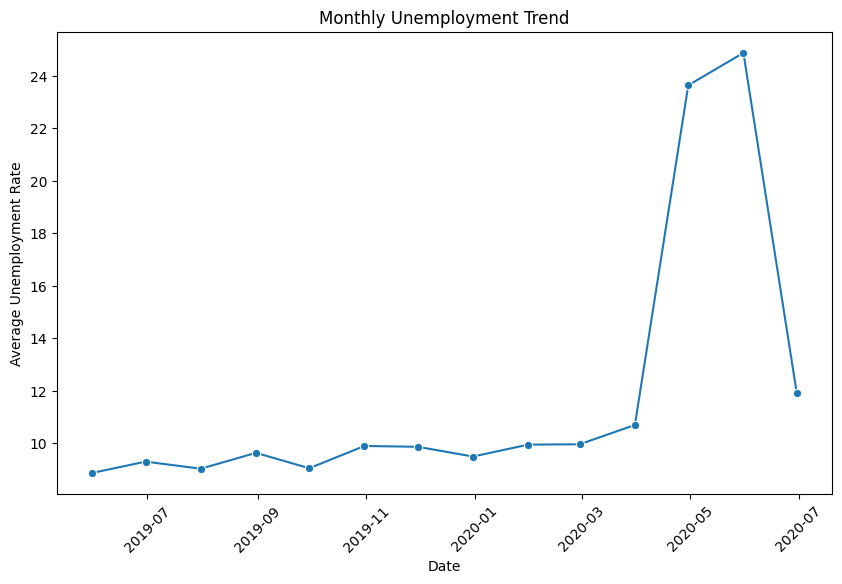

In [ ]:
plt.figure(figsize=(10,6))
sns.lineplot(x=monthly_unemployment.index,y=monthly_unemployment.values,marker="o")
plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate")
plt.title("Monthly Unemployment Trend")
plt.xticks(rotation=45)
plt.show()

The average unemployment rate remained relatively stable at around 9–10% from May 2019 to February 2020. It increased in March 2020 and rose sharply in April and May 2020, reaching approximately 23.64% and 24.88%, respectively. The rate then declined substantially in June 2020. The sharp increase coincides with the COVID-19 period in India, indicating a strong temporal association.

In [ ]:
selected_regions = ["Maharashtra", "Haryana", "Bihar"]
state_df = df[df["Region"].isin(selected_regions)]
state_df

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
26,Bihar,2019-05-31,Monthly,9.27,24322330.0,39.75,Rural
27,Bihar,2019-06-30,Monthly,10.20,24097712.0,39.71,Rural
28,Bihar,2019-07-31,Monthly,13.44,23248875.0,39.66,Rural
29,Bihar,2019-08-31,Monthly,11.00,22260203.0,36.85,Rural
30,Bihar,2019-09-30,Monthly,8.87,23905700.0,38.57,Rural
...,...,...,...,...,...,...,...
584,Maharashtra,2020-02-29,Monthly,5.34,17122782.0,37.61,Urban
585,Maharashtra,2020-03-31,Monthly,6.34,17065830.0,37.80,Urban
586,Maharashtra,2020-04-30,Monthly,14.99,12674451.0,30.86,Urban
587,Maharashtra,2020-05-31,Monthly,15.92,12365754.0,30.38,Urban


In [ ]:
state_df[["Region", " Date", " Estimated Unemployment Rate (%)"]]

,Region,Date,Estimated Unemployment Rate (%)
26,Bihar,2019-05-31,9.27
27,Bihar,2019-06-30,10.20
28,Bihar,2019-07-31,13.44
29,Bihar,2019-08-31,11.00
30,Bihar,2019-09-30,8.87
...,...,...,...
584,Maharashtra,2020-02-29,5.34
585,Maharashtra,2020-03-31,6.34
586,Maharashtra,2020-04-30,14.99
587,Maharashtra,2020-05-31,15.92


In [ ]:
state_monthly=state_df.groupby(["Region"," Date"])[" Estimated Unemployment Rate (%)"].mean().reset_index()
state_monthly

,Region,Date,Estimated Unemployment Rate (%)
0,Bihar,2019-05-31,14.585
1,Bihar,2019-06-30,11.745
2,Bihar,2019-07-31,14.925
3,Bihar,2019-08-31,14.330
4,Bihar,2019-09-30,14.665
5,Bihar,2019-10-31,13.265
6,Bihar,2019-11-30,15.010
7,Bihar,2019-12-31,12.535
8,Bihar,2020-01-31,14.910
9,Bihar,2020-02-29,12.360


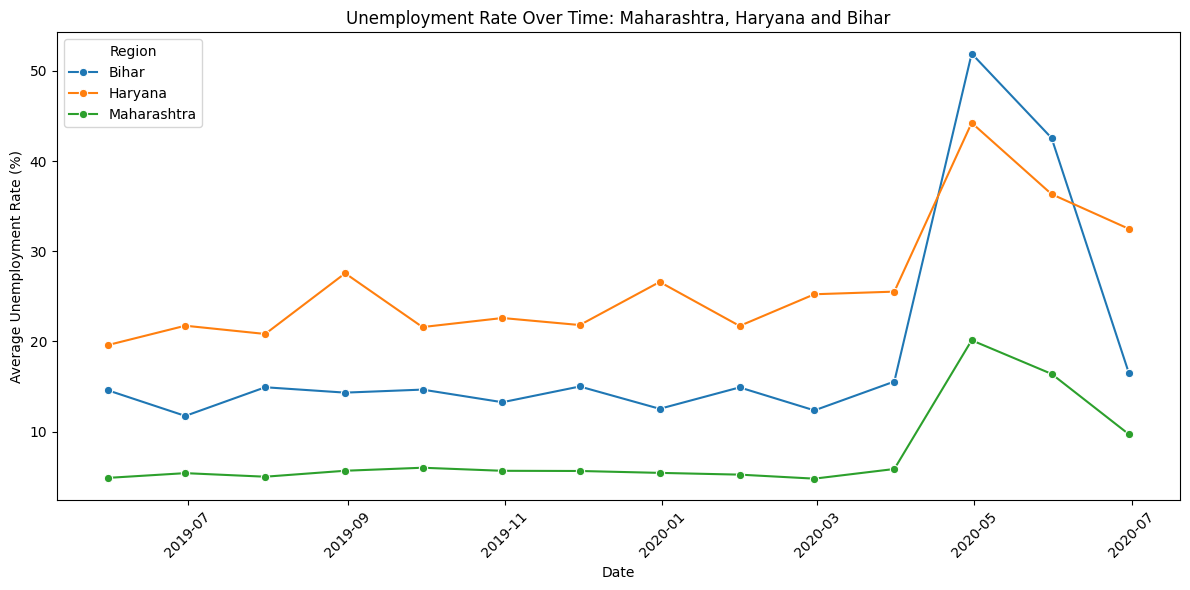

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=state_monthly,
    x=" Date",
    y=" Estimated Unemployment Rate (%)",
    hue="Region",
    marker="o"
)

plt.xlabel("Date")
plt.ylabel("Average Unemployment Rate (%)")
plt.title("Unemployment Rate Over Time: Maharashtra, Haryana and Bihar")
plt.xticks(rotation=45)
plt.legend(title="Region")
plt.tight_layout()
plt.show()

Bihar and Haryana generally recorded higher unemployment rates than Maharashtra throughout the observed period. All three regions experienced a sharp increase in unemployment around April–May 2020, with Bihar showing the largest spike. The rates declined again in June 2020. The simultaneous increase across the three regions indicates a strong temporal association with the COVID-19 period.

Co-Relation

In [ ]:
corr_df=df[[" Estimated Unemployment Rate (%)"," Estimated Employed"," Estimated Labour Participation Rate (%)"]]
#Calculation of Pearson Correlation coefficient

In [ ]:
corr_matrix = corr_df.corr()
corr_matrix

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


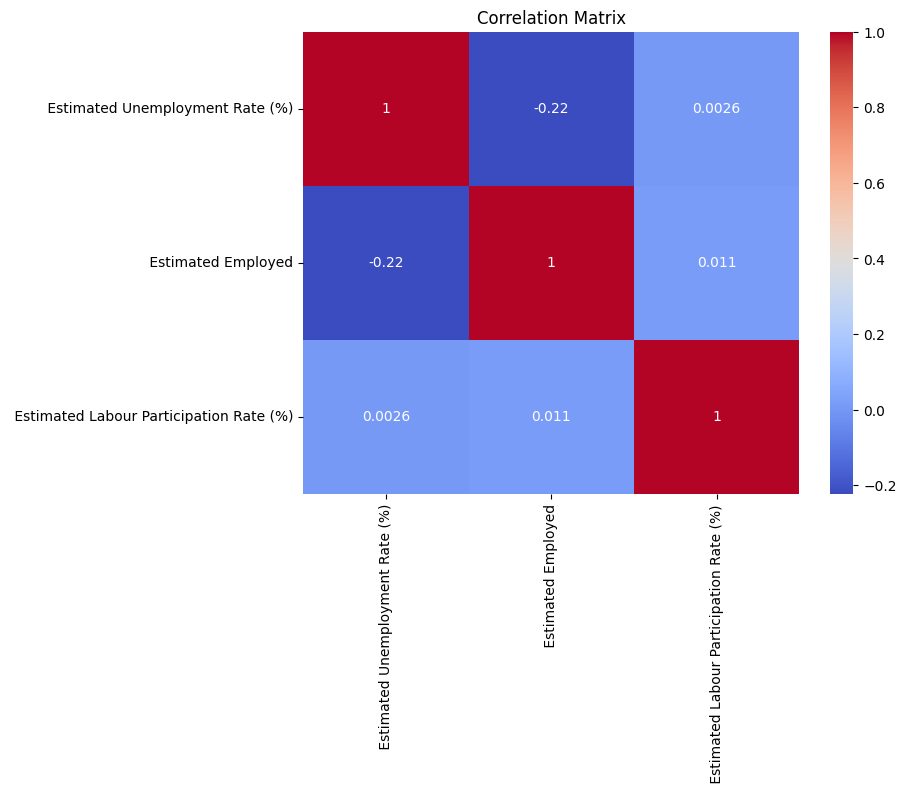

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

The correlation analysis shows a weak negative relationship (-0.22) between the estimated unemployment rate and estimated employed population. The unemployment rate and estimated labour participation rate have an almost zero correlation (0.0026), indicating little linear association between the two variables in this dataset. Similarly, estimated employed and labour participation rate show an almost zero correlation (0.011). These results describe linear associations in the dataset and do not imply causal relationships.

Pre-COVID vs. post-COVID comparison

In [ ]:
pre_covid = df[df[" Date"] < "2020-03-01"]
covid_period = df[df[" Date"] >= "2020-03-01"]

In [ ]:
len(pre_covid)

536

In [ ]:
len(covid_period)

204

In [ ]:
pre_covid_unemp=pre_covid[" Estimated Unemployment Rate (%)"].mean()
covid_dur_unemp=covid_period[" Estimated Unemployment Rate (%)"].mean()

In [ ]:
pre_covid_unemp

np.float64(9.509533582089553)

In [ ]:
covid_dur_unemp

np.float64(17.774362745098042)

In [ ]:
diff=covid_dur_unemp-pre_covid_unemp
diff

np.float64(8.26482916300849)

In [ ]:
perc_diff=(diff/pre_covid_unemp)*100
perc_diff

np.float64(86.91098350580133)

Text(0.5, 1.0, 'Unemployment Rate Comparison: Pre-COVID vs. COVID-Period')

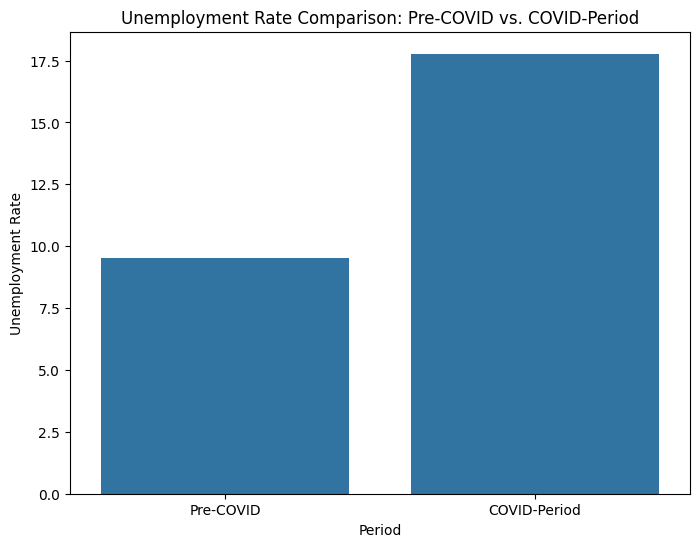

In [ ]:
comparision=pd.DataFrame({
    "Period":["Pre-COVID","COVID-Period"],
    "Unemployment Rate":[pre_covid_unemp,covid_dur_unemp]
})
plt.figure(figsize=(8,6))
sns.barplot(x="Period",y="Unemployment Rate",data=comparision)
plt.xlabel("Period")
plt.ylabel("Unemployment Rate")
plt.title("Unemployment Rate Comparison: Pre-COVID vs. COVID-Period")

The average unemployment rate was approximately 9.51% during the pre-COVID period and increased to approximately 17.77% during the COVID-period. This represents an increase of about 8.26 percentage points, or approximately 86.9% relative to the pre-COVID average. The substantial increase indicates a strong association between the COVID-period and higher unemployment rates in the observed dataset.

# Final Findings

### 1. Regional Differences
The regional analysis shows substantial differences in average unemployment rates across the regions. Tripura recorded the highest average unemployment rate at approximately 28.35%, followed by Haryana at 26.28% and Jharkhand at 20.59%.

### 2. Unemployment Trend Over Time
The average unemployment rate remained relatively stable at around 9–10% from May 2019 to February 2020. It increased in March 2020 and rose sharply during April and May 2020, reaching approximately 23.64% and 24.88%, respectively. The rate declined substantially in June 2020.

### 3. Regional COVID-Period Comparison
Bihar, Haryana and Maharashtra all experienced a substantial increase in unemployment around April–May 2020. Bihar recorded the largest spike among the three regions, while Maharashtra remained comparatively lower.

### 4. Pre-COVID vs COVID-Period
The average unemployment rate increased from approximately 9.51% during the pre-COVID period to approximately 17.77% during the COVID-period. This represents an increase of about 8.26 percentage points, or approximately 86.9% relative to the pre-COVID average.

### 5. Correlation Analysis
The correlation analysis showed a weak negative correlation (-0.22) between unemployment rate and estimated employed population. The correlation between unemployment rate and labour participation rate was approximately zero (0.0026), indicating little linear association between these variables in the dataset.

### 6. Overall Conclusion
The analysis reveals clear regional and temporal differences in unemployment rates. A sharp increase in unemployment occurred during April and May 2020, coinciding with the COVID-19 period. The results demonstrate a strong temporal association between the COVID-period and increased unemployment in the observed data. However, the analysis is exploratory and correlation-based, so it does not establish that COVID-19 alone caused the observed changes.